# Parte 1 — MDP + Q-Learning tabular (despacho de batería / BESS) con datos reales de XM

**Problema:** desplazamiento de demanda (*load shifting*), no especulación financiera.
La batería compra energía a la red cuando el precio de bolsa es bajo y cubre demanda
propia (costo evitado) cuando es alto, respetando las restricciones físicas del BESS.

Flujo del notebook:
1. Cargar el precio de bolsa nacional horario real (`PrecBolsNaci`) de XM con `pydataxm`.
   Cada descarga actualiza el respaldo `data/raw/xm_precio_bolsa.csv`; si la API falla se usa ese CSV.
2. Dividir los días en orden cronológico: 70 % entrenamiento, 15 % validación, 15 % prueba.
   El cuartil de precio de cada hora se calcula con una **ventana móvil causal** de las
   168 h anteriores, así el estado distingue horas baratas y caras aunque cambie el nivel
   de precios entre meses secos y húmedos.
3. Q-Learning con dos cambios de diseño: *reward shaping* basado en potencial y tasa de
   aprendizaje que decrece con las visitas. El exponente de la tasa y el decaimiento de ε se
   eligen **solo con validación** (varias semillas).
4. Entrenar `QLearningAgent` 5,000 episodios (escenario *base*) con los hiperparámetros elegidos.
5. Calcular la política de referencia por **Iteración de Valores** sobre el modelo empírico de entrenamiento.
6. Reportar en **prueba** (días nunca usados para decidir nada) el ahorro de la Línea Base justa,
   Q-Learning (diseño anterior y nuevo) e Iteración de Valores.
7. Escenarios por presupuesto de entrenamiento (50, 5,000 y 50,000 episodios) y por eficiencia de
   ida y vuelta de la batería (70 % a 100 %), con su curva de aprendizaje, para el dashboard.

In [1]:
from __future__ import annotations
import sys
import time
from datetime import date
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.data.download_xm import obtener_serie_horaria
from src.part1_rl.environment import BatteryEnv, Accion, umbrales_moviles, VENTANA_CUARTILES_H
from src.part1_rl.agent import QLearningAgent
from src.part1_rl.value_iteration import value_iteration_policy

SEMILLA = 42
EPISODIOS = 5000  # escenario base
ESCENARIOS_EPISODIOS = {"corto": 50, "base": EPISODIOS, "largo": 50_000}
# Eficiencias de ida y vuelta (%) y presupuestos de la curva de aprendizaje (sección 6).
EFICIENCIAS_PCT = [70, 75, 80, 85, 90, 95, 100]
PRESUPUESTOS_CURVA = [50, 300, 1000, 2000, 5000, 20_000, 50_000]
FRACCION_TRAIN, FRACCION_VAL = 0.70, 0.15  # el 15 % restante es prueba
# Periodo fijo (365 días) para que los resultados sean reproducibles.
USAR_XM = True
# XM revisa los precios de días recientes: para que los resultados sean reproducibles se usa
# el respaldo versionado data/raw/xm_precio_bolsa.csv. True vuelve a descargar de la API.
ACTUALIZAR_DESDE_API = False
FECHA_INICIO, FECHA_FIN = date(2025, 11, 10), date(2026, 11, 9)
# Con 1 kWh por escalón (batería de 4 kWh) la recompensa es exactamente ±precio (COP/kWh).
ENERGIA_POR_NIVEL_KWH = 1.0
GAMMA = 0.99
PENALIZACION = -1000.0

## 1. Datos reales de precio horario (XM)

`PrecBolsNaci` llega en formato ancho (`Date`, `Values_Hour01` … `Values_Hour24`, en COP/kWh).
`a_serie_horaria` (en `src/data/download_xm.py`) lo convierte a una fila por hora y descarta días
incompletos. `Values_Hour01` corresponde al periodo 00:00-01:00.

Por defecto se lee el respaldo versionado `data/raw/xm_precio_bolsa.csv` (descargado de la API el
2026-11-12), porque XM revisa los precios de días recientes y una descarga nueva puede cambiar las
cifras. Con `ACTUALIZAR_DESDE_API = True` se descarga de nuevo y se actualiza el respaldo.

In [2]:
if not USAR_XM:
    raise RuntimeError("Este notebook reporta resultados con datos reales: deja USAR_XM = True.")
df_precios, ORIGEN = obtener_serie_horaria(FECHA_INICIO, FECHA_FIN, actualizar=ACTUALIZAR_DESDE_API)
FUENTE = "XM PrecBolsNaci"
df_precios["fecha"] = df_precios["timestamp"].dt.date
df_precios["hora"] = df_precios["timestamp"].dt.hour
print(f"Origen: {ORIGEN} | días: {df_precios['fecha'].nunique()} | horas: {len(df_precios)} | "
      f"{df_precios['fecha'].min()} a {df_precios['fecha'].max()}")
print(df_precios["precio_cop_kwh"].describe().round(1))

[OK] Usando el respaldo versionado xm_precio_bolsa.csv (sin consultar la API).
Origen: XM respaldo CSV | días: 365 | horas: 8760 | 2025-11-10 a 2026-11-09
count    8760.0
mean      456.8
std       304.5
min        97.7
25%       208.3
50%       357.6
75%       680.4
max      1902.6
Name: precio_cop_kwh, dtype: float64


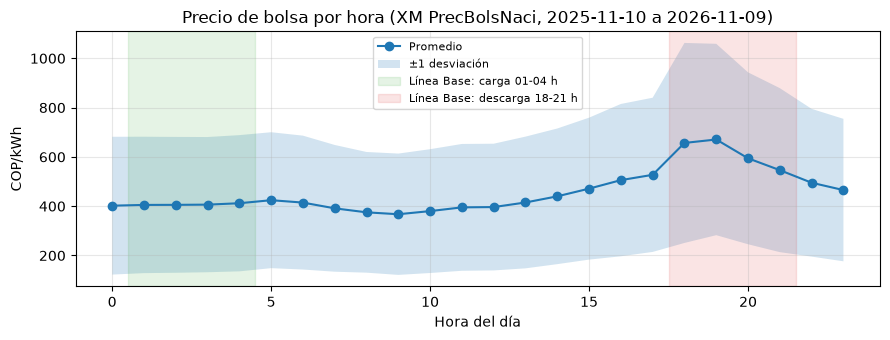

In [3]:
perfil = df_precios.groupby("hora")["precio_cop_kwh"].agg(["mean", "std"])
plt.figure(figsize=(9, 3.5))
plt.plot(perfil.index, perfil["mean"], marker="o", label="Promedio")
plt.fill_between(perfil.index, perfil["mean"] - perfil["std"], perfil["mean"] + perfil["std"],
                 alpha=0.2, label="±1 desviación")
plt.axvspan(0.5, 4.5, color="tab:green", alpha=0.12, label="Línea Base: carga 01-04 h")
plt.axvspan(17.5, 21.5, color="tab:red", alpha=0.12, label="Línea Base: descarga 18-21 h")
plt.title(f"Precio de bolsa por hora ({FUENTE}, {FECHA_INICIO} a {FECHA_FIN})")
plt.xlabel("Hora del día"); plt.ylabel("COP/kWh"); plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 2. División cronológica 70 / 15 / 15 y entornos

- **Entrenamiento:** el agente aprende y se estima el modelo empírico de Iteración de Valores.
- **Validación:** solo para elegir `alpha` y el decaimiento de ε.
- **Prueba:** solo para reportar las métricas finales.

**Cuartiles con ventana móvil causal:** los umbrales (p25, p50, p75) de la hora *t* se calculan con
las 168 horas anteriores (*t*−168 … *t*−1), nunca con la hora actual ni con el futuro. Se calculan una
sola vez sobre la serie completa y se recortan por conjunto, así la primera semana de validación usa
el final de entrenamiento y la de prueba el final de validación (pasado, no futuro). Las primeras 168 h
de la serie usan los cuartiles de esa primera semana de entrenamiento.

Entrenamiento  255 días  2025-11-10 a 2026-07-22
Validación      55 días  2026-07-23 a 2026-09-15
Prueba          55 días  2026-09-16 a 2026-11-09
Umbrales p25/p50/p75 al inicio de entrenamiento: [183.5 273.  282.5]
Umbrales p25/p50/p75 al inicio de prueba:       [425.5 491.7 591.1]
Cuartiles fijos de todo el entrenamiento (antes): [154.4 265.5 432.3]


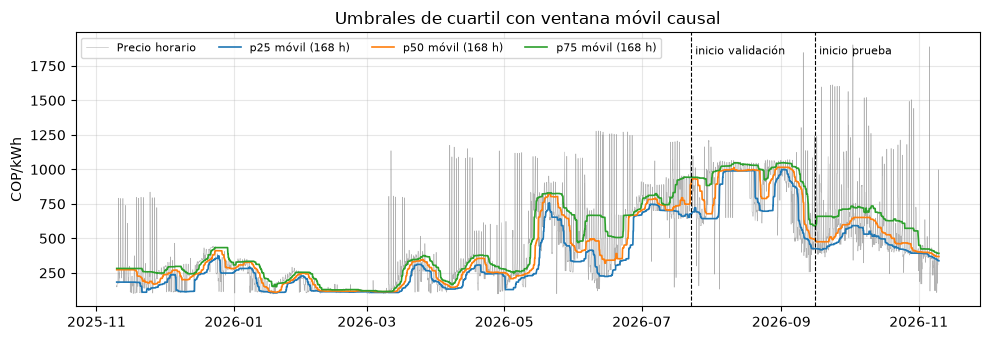

In [4]:
fechas = sorted(df_precios["fecha"].unique())
n = len(fechas)
corte_train, corte_val = int(n * FRACCION_TRAIN), int(n * (FRACCION_TRAIN + FRACCION_VAL))
fechas_train, fechas_val, fechas_test = fechas[:corte_train], fechas[corte_train:corte_val], fechas[corte_val:]

def precios_de(fechas_sub):
    return df_precios[df_precios["fecha"].isin(fechas_sub)]["precio_cop_kwh"].to_numpy()

precios_train, precios_val, precios_test = map(precios_de, (fechas_train, fechas_val, fechas_test))

def crear_env(precios, aleatorio=False, semilla=None, umbrales=None):
    return BatteryEnv(precios, soc_inicial=0, penalizacion_invalida=PENALIZACION,
                      energia_por_nivel_kwh=ENERGIA_POR_NIVEL_KWH, umbrales_precio=umbrales,
                      aleatorio=aleatorio, semilla=semilla)

# Umbrales causales por hora sobre la serie completa (orden cronológico, sin huecos).
serie_completa = df_precios["precio_cop_kwh"].to_numpy()
assert np.array_equal(serie_completa, np.concatenate([precios_train, precios_val, precios_test]))
UMBRALES_HORA = umbrales_moviles(serie_completa, VENTANA_CUARTILES_H)
n_tr, n_va = len(precios_train), len(precios_val)
UMB_TRAIN = UMBRALES_HORA[:n_tr]
UMB_VAL = UMBRALES_HORA[n_tr:n_tr + n_va]
UMB_TEST = UMBRALES_HORA[n_tr + n_va:]
env_val = crear_env(precios_val, umbrales=UMB_VAL)
env_test = crear_env(precios_test, umbrales=UMB_TEST)

for nombre, f in (("Entrenamiento", fechas_train), ("Validación", fechas_val), ("Prueba", fechas_test)):
    print(f"{nombre:<14} {len(f):>3} días  {f[0]} a {f[-1]}")
print("Umbrales p25/p50/p75 al inicio de entrenamiento:", UMB_TRAIN[0].round(1))
print("Umbrales p25/p50/p75 al inicio de prueba:      ", UMB_TEST[0].round(1))
print("Cuartiles fijos de todo el entrenamiento (antes):", np.quantile(precios_train, [.25, .5, .75]).round(1))

umb = pd.DataFrame(UMBRALES_HORA, columns=["p25", "p50", "p75"], index=df_precios["timestamp"])
plt.figure(figsize=(10, 3.5))
plt.plot(df_precios["timestamp"], serie_completa, lw=0.4, color="gray", alpha=0.6, label="Precio horario")
for c in umb.columns:
    plt.plot(umb.index, umb[c], lw=1.2, label=f"{c} móvil (168 h)")
for f, nombre in ((fechas_val[0], "inicio validación"), (fechas_test[0], "inicio prueba")):
    plt.axvline(pd.Timestamp(f), color="k", ls="--", lw=0.8)
    plt.text(pd.Timestamp(f), plt.ylim()[1] * 0.92, f" {nombre}", fontsize=8)
plt.title("Umbrales de cuartil con ventana móvil causal"); plt.ylabel("COP/kWh")
plt.legend(fontsize=8, ncol=4); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [5]:
def evaluar(env: BatteryEnv, selector) -> pd.DataFrame:
    """Ejecuta `selector(estado) -> accion` sobre todos los días del entorno (sin exploración)."""
    filas = []
    for dia in range(env.n_dias):
        estado = env.reset(dia=dia)
        terminado = False
        while not terminado:
            estado, _, terminado, info = env.step(selector(estado))
            filas.append(info)
    df = pd.DataFrame(filas)
    df["accion"] = df["accion"].map(lambda a: Accion(a).name)
    df["ahorro_acumulado_cop"] = df["flujo_caja_cop"].cumsum()
    return df

def ahorro(env, selector) -> float:
    return float(evaluar(env, selector)["flujo_caja_cop"].sum())

def entrenar_agente(alpha_exponente, frac_decaimiento, semilla, episodios=EPISODIOS, eficiencia=1.0):
    """Diseño nuevo: reward shaping basado en potencial + alpha = 1 / n(s,a)^ω.

    ``eficiencia`` (ida y vuelta) se usa en el entorno de entrenamiento: la descarga evita
    ``eficiencia · precio · kWh``. Con 1.0 la batería es ideal (escenario de la QA y del agente).
    """
    agente = QLearningAgent(n_acciones=BatteryEnv.N_ACCIONES, gamma=GAMMA,
                            epsilon_inicial=1.0, epsilon_final=0.05,
                            episodios_decaimiento=int(episodios * frac_decaimiento), semilla=semilla,
                            alpha_exponente=alpha_exponente)
    env_train = BatteryEnv(precios_train, soc_inicial=0, penalizacion_invalida=PENALIZACION,
                           energia_por_nivel_kwh=ENERGIA_POR_NIVEL_KWH, umbrales_precio=UMB_TRAIN,
                           aleatorio=True, semilla=semilla, gamma_shaping=GAMMA,
                           eficiencia=eficiencia)
    retornos = agente.entrenar(env_train, episodios=episodios)
    return agente, retornos

def entrenar_agente_anterior(semilla, alpha=0.3, frac_decaimiento=0.8):
    """Diseño anterior (para comparar): alpha fijo y recompensa sin shaping."""
    agente = QLearningAgent(n_acciones=BatteryEnv.N_ACCIONES, alpha=alpha, gamma=GAMMA,
                            epsilon_inicial=1.0, epsilon_final=0.05,
                            episodios_decaimiento=int(EPISODIOS * frac_decaimiento), semilla=semilla)
    env_train = crear_env(precios_train, aleatorio=True, semilla=semilla, umbrales=UMB_TRAIN)
    agente.entrenar(env_train, episodios=EPISODIOS)
    return agente

greedy = lambda ag: (lambda s: ag.seleccionar_accion(s, explorar=False))

## 3. Diseño del aprendizaje y selección de hiperparámetros (solo validación)

**Por qué fallaba el diseño anterior** (α = 0.3 fijo, recompensa = flujo de caja):

1. *La recompensa llega tarde.* Cargar de madrugada cuesta de inmediato, y la recompensa de descargar
   llega 15 a 18 horas después. Q-Learning la propaga hacia atrás un paso por episodio, a través de
   cuartiles que cambian al azar, así que aprende primero que "cargar cuesta".
2. *α fijo con recompensas ruidosas.* Con α = 0.3, cada Q(s,a) es casi un promedio de los últimos 3 o 4
   días, nunca converge, y el `max` convierte ese ruido en sobreestimación.

**Los dos cambios:**

- *Reward shaping basado en potencial* (Ng, Harada y Russell, 1999). Se valora la energía guardada a la
  mediana causal del precio: `Φ = SoC · kWh por escalón · p50_t`, y la recompensa de entrenamiento es
  `R + γ·Φ(s') − Φ(s)`, con `Φ = 0` al terminar el día. Cargar por debajo de la mediana o descargar por
  encima da recompensa positiva inmediata. Solo se usa para entrenar: el ahorro se sigue midiendo con el
  flujo de caja real.
- *Tasa que decrece con las visitas:* `α(s,a) = 1 / n(s,a)^ω`, que cumple las condiciones de convergencia
  de Robbins-Monro y hace que cada Q promedie sus recompensas.

**Búsqueda:** ω ∈ {0.6, 0.7, 0.8, 1.0} × fracción de episodios en que ε decae de 1.0 a 0.05 ∈ {0.5, 0.8},
5 semillas por combinación y 5,000 episodios cada una. Se elige la mayor media en validación. Los días de
prueba no intervienen. Al final se compara con el diseño anterior en las mismas semillas.

In [6]:
EXPONENTES = [0.6, 0.7, 0.8, 1.0]
DECAIMIENTOS = [0.5, 0.8]
SEMILLAS_BUSQUEDA = [0, 1, 2, 3, 4]

t0 = time.time()
filas = []
for omega in EXPONENTES:
    for frac in DECAIMIENTOS:
        for semilla in SEMILLAS_BUSQUEDA:
            ag, _ = entrenar_agente(omega, frac, semilla)
            filas.append({"omega": omega, "decaimiento": frac, "semilla": semilla,
                          "ahorro_val": ahorro(env_val, greedy(ag))})
busqueda = (pd.DataFrame(filas).groupby(["omega", "decaimiento"])["ahorro_val"]
            .agg(media="mean", desv="std", minimo="min").round(0).sort_values("media", ascending=False))
mejor_omega, mejor_decaimiento = busqueda.index[0]
anterior_val = [ahorro(env_val, greedy(entrenar_agente_anterior(s))) for s in SEMILLAS_BUSQUEDA]
base_val = ahorro(env_val, BatteryEnv.naive_policy)
print(f"Búsqueda: {len(filas)} entrenamientos en {time.time() - t0:.0f} s")
print(f"Elegido: ω = {mejor_omega}, ε decae en el {mejor_decaimiento:.0%} de los episodios")
print(f"Validación — Línea Base: {base_val:,.0f} COP | diseño anterior (α=0.3 fijo): "
      f"{np.mean(anterior_val):,.0f} ± {np.std(anterior_val, ddof=1):,.0f} | diseño nuevo: "
      f"{busqueda.iloc[0]['media']:,.0f} ± {busqueda.iloc[0]['desv']:,.0f} COP")
busqueda

Búsqueda: 40 entrenamientos en 117 s
Elegido: ω = 0.7, ε decae en el 50% de los episodios
Validación — Línea Base: 38,598 COP | diseño anterior (α=0.3 fijo): 23,550 ± 8,511 | diseño nuevo: 49,322 ± 1,345 COP


media    desv   minimo
omega decaimiento                          
0.7   0.5          49322.0  1345.0  47802.0
0.6   0.5          48677.0  1147.0  46643.0
1.0   0.5          47057.0  2833.0  43918.0
0.8   0.8          47048.0  4158.0  40530.0
      0.5          46597.0  2692.0  44321.0
1.0   0.8          45200.0  3325.0  42138.0
0.7   0.8          44938.0  6064.0  34946.0
0.6   0.8          42540.0  4484.0  35988.0

## 4. Entrenamiento final (escenario base: 5,000 episodios) y política de referencia

El agente final se entrena con los hiperparámetros elegidos y `SEMILLA = 42` (fijada de antemano).
La política de referencia resuelve el mismo MDP con Iteración de Valores sobre las probabilidades de
transición de cuartil y los precios medios estimados con los días de entrenamiento.

Episodios: 5000 | epsilon final: 0.050 | estados visitados: 438 de 480


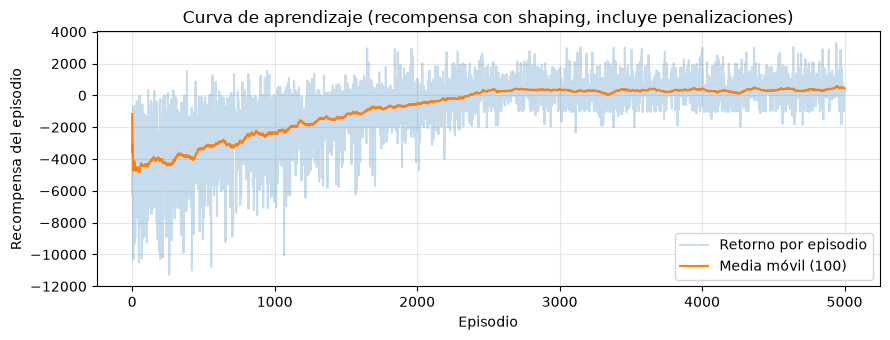

Iteración de Valores: convergió en 25 barridos


In [7]:
agente, retornos = entrenar_agente(mejor_omega, mejor_decaimiento, SEMILLA)
print(f"Episodios: {len(retornos)} | epsilon final: {agente.epsilon:.3f} | "
      f"estados visitados: {len(agente.q_table)} de {24 * 4 * 5}")

serie = pd.Series(retornos)
plt.figure(figsize=(9, 3.5))
plt.plot(serie, alpha=0.25, label="Retorno por episodio")
plt.plot(serie.rolling(100, min_periods=1).mean(), label="Media móvil (100)")
plt.title("Curva de aprendizaje (recompensa con shaping, incluye penalizaciones)")
plt.xlabel("Episodio"); plt.ylabel("Recompensa del episodio")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

referencia = value_iteration_policy(precios_train, UMB_TRAIN, ENERGIA_POR_NIVEL_KWH, GAMMA, PENALIZACION)
print(f"Iteración de Valores: convergió en {referencia.iteraciones} barridos")

In [8]:
# Artefactos para `simular()` y la herramienta `simular_despacho` del agente LLM (Parte 2).
DIR_PROCESADO = RAIZ / "data" / "processed"
ruta_eval = DIR_PROCESADO / "precios_evaluacion.csv"
eval_df = df_precios[df_precios["fecha"].isin(fechas_test)][["timestamp", "precio_cop_kwh"]].copy()
eval_df[["umbral_p25", "umbral_p50", "umbral_p75"]] = UMB_TEST  # umbrales causales de cada hora
eval_df.to_csv(ruta_eval, index=False)
ruta_val = DIR_PROCESADO / "precios_validacion.csv"
val_df = df_precios[df_precios["fecha"].isin(fechas_val)][["timestamp", "precio_cop_kwh"]].copy()
val_df[["umbral_p25", "umbral_p50", "umbral_p75"]] = UMB_VAL
val_df.to_csv(ruta_val, index=False)
ruta_ref = referencia.guardar(DIR_PROCESADO / "politica_referencia.json",
                              metadatos={"fuente_datos": FUENTE,
                                         "fechas_entrenamiento": [str(fechas_train[0]), str(fechas_train[-1])]})
METADATOS = dict(
    fuente_datos=FUENTE,
    origen_datos=ORIGEN,
    cuartiles="ventana movil causal",
    ventana_cuartiles_h=VENTANA_CUARTILES_H,
    soc_inicial=0,
    penalizacion_invalida=PENALIZACION,
    energia_por_nivel_kwh_entrenamiento=ENERGIA_POR_NIVEL_KWH,
    diseno="reward shaping (potencial p50 movil) + alpha = 1/n^omega",
    alpha_exponente=mejor_omega,
    fraccion_decaimiento_epsilon=mejor_decaimiento,
    fechas_entrenamiento=[str(fechas_train[0]), str(fechas_train[-1])],
    fechas_validacion=[str(fechas_val[0]), str(fechas_val[-1])],
    fechas_evaluacion=[str(fechas_test[0]), str(fechas_test[-1])],
    archivo_precios_evaluacion=ruta_eval.name,
    archivo_precios_validacion=ruta_val.name,
    archivo_politica_referencia=ruta_ref.name,
)
ruta_q = agente.guardar(DIR_PROCESADO / "q_table.json",
                        metadatos={**METADATOS, "escenario": "base", "episodios": EPISODIOS,
                                   "eficiencia_entrenamiento": 1.0})
print(f"Guardados: {ruta_q.name}, {ruta_ref.name}, {ruta_eval.name}, {ruta_val.name}")

Guardados: q_table.json, politica_referencia.json, precios_evaluacion.csv, precios_validacion.csv


## 5. Evaluación en prueba: ahorro acumulado (COP)

Cada política recorre todos los días de prueba en orden, sin exploración, con la batería vacía al
inicio de cada día. El ahorro usa el flujo de caja real (`info["flujo_caja_cop"]`), sin la penalización
artificial. Como cota superior (no implementable) se agrega el óptimo con **información perfecta**:
programación dinámica por día conociendo los 24 precios reales de antemano.

In [9]:
def optimo_informacion_perfecta(precios, energia=ENERGIA_POR_NIVEL_KWH) -> float:
    total = 0.0
    for p in np.asarray(precios).reshape(-1, 24):
        V = np.full(5, -np.inf); V[0] = 0.0
        for precio in p:
            nuevo = V.copy()                                           # mantener
            nuevo[1:] = np.maximum(nuevo[1:], V[:-1] - precio * energia)  # cargar
            nuevo[:-1] = np.maximum(nuevo[:-1], V[1:] + precio * energia)  # descargar
            V = nuevo
        total += V.max()
    return total

df_base = evaluar(env_test, BatteryEnv.naive_policy)
df_ql = evaluar(env_test, greedy(agente))
df_ref = evaluar(env_test, referencia.accion)
agente_anterior = entrenar_agente_anterior(SEMILLA)
df_ql_anterior = evaluar(env_test, greedy(agente_anterior))
cota = optimo_informacion_perfecta(precios_test)

def fila(df):
    return {"Ahorro acumulado (COP)": df["flujo_caja_cop"].sum(),
            "Cargas": int(((df["accion"] == "CARGAR") & df["valida"]).sum()),
            "Descargas": int(((df["accion"] == "DESCARGAR") & df["valida"]).sum()),
            "Acciones inválidas": int((~df["valida"]).sum())}

tabla = pd.DataFrame({
    "Línea Base justa (01-04 h / 18-21 h)": fila(df_base),
    "Q-Learning diseño anterior (α=0.3 fijo, 5,000 ep.)": fila(df_ql_anterior),
    f"Q-Learning diseño nuevo (shaping + α=1/n^{mejor_omega}, 5,000 ep.)": fila(df_ql),
    "Iteración de Valores (referencia)": fila(df_ref),
}).T
tabla["% de la cota superior"] = (100 * tabla["Ahorro acumulado (COP)"] / cota).round(1)
tabla["vs. Línea Base"] = (100 * (tabla["Ahorro acumulado (COP)"] / tabla.iloc[0, 0] - 1)).round(1).map("{:+.1f} %".format)
tabla["Ahorro acumulado (COP)"] = tabla["Ahorro acumulado (COP)"].round(0)
print(f"Prueba: {len(fechas_test)} días ({fechas_test[0]} a {fechas_test[-1]}), batería de 4 kWh (1 kWh por escalón)")
print(f"Cota superior con información perfecta: {cota:,.0f} COP")
tabla

Prueba: 55 días (2026-09-16 a 2026-11-09), batería de 4 kWh (1 kWh por escalón)
Cota superior con información perfecta: 109,546 COP


,Ahorro acumulado (COP),Cargas,Descargas,Acciones inválidas,% de la cota superior,vs. Línea Base
Línea Base justa (01-04 h / 18-21 h),89338.0,220.0,220.0,0.0,81.6,+0.0 %
"Q-Learning diseño anterior (α=0.3 fijo, 5,000 ep.)",37854.0,152.0,152.0,0.0,34.6,-57.6 %
"Q-Learning diseño nuevo (shaping + α=1/n^0.7, 5,000 ep.)",82222.0,392.0,392.0,0.0,75.1,-8.0 %
Iteración de Valores (referencia),95134.0,415.0,415.0,0.0,86.8,+6.5 %


In [10]:
# Robustez: mismo entrenamiento final con 5 semillas distintas, evaluado en prueba.
ahorros_semillas = [ahorro(env_test, greedy(entrenar_agente(mejor_omega, mejor_decaimiento, s)[0]))
                    for s in (42, 7, 13, 21, 99)]
print("Q-Learning en prueba por semilla:", [f"{a:,.0f}" for a in ahorros_semillas])
print(f"Media {np.mean(ahorros_semillas):,.0f} COP ± {np.std(ahorros_semillas, ddof=1):,.0f}")

Q-Learning en prueba por semilla: ['82,222', '82,873', '92,070', '80,733', '87,071']
Media 84,994 COP ± 4,602


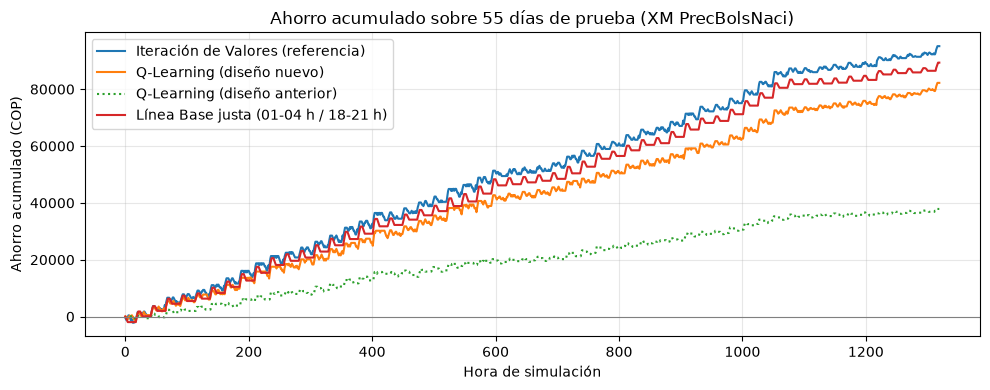

In [11]:
plt.figure(figsize=(10, 4))
plt.plot(df_ref["ahorro_acumulado_cop"].to_numpy(), label="Iteración de Valores (referencia)")
plt.plot(df_ql["ahorro_acumulado_cop"].to_numpy(), label="Q-Learning (diseño nuevo)")
plt.plot(df_ql_anterior["ahorro_acumulado_cop"].to_numpy(), ls=":", label="Q-Learning (diseño anterior)")
plt.plot(df_base["ahorro_acumulado_cop"].to_numpy(), label="Línea Base justa (01-04 h / 18-21 h)")
plt.axhline(0, color="gray", lw=0.8)
plt.title(f"Ahorro acumulado sobre {env_test.n_dias} días de prueba ({FUENTE})")
plt.xlabel("Hora de simulación"); plt.ylabel("Ahorro acumulado (COP)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [12]:
# Comprobación: simular() (lo que usa el agente LLM) reproduce las cifras del notebook.
from src.part1_rl.simulacion import simular
r = simular(4.0)
print(f"simular(4 kWh): Q-Learning {r.ahorro_qlearning_cop:,.0f} | Línea Base {r.ahorro_base_cop:,.0f} | "
      f"Iteración de Valores {r.ahorro_referencia_cop:,.0f} COP")
assert np.isclose(r.ahorro_qlearning_cop, df_ql["flujo_caja_cop"].sum())
assert np.isclose(r.ahorro_base_cop, df_base["flujo_caja_cop"].sum())
assert np.isclose(r.ahorro_referencia_cop, df_ref["flujo_caja_cop"].sum())
r.traza.head(26)

simular(4 kWh): Q-Learning 82,222 | Línea Base 89,338 | Iteración de Valores 95,134 COP


,timestamp,precio_cop,soc_rl,accion_rl,ahorro_acum_rl,ahorro_acum_base,ahorro_acum_ref
0,2026-09-16 00:00:00,442.35587,0.0,MANTENER,0.00000,0.00000,-442.35587
1,2026-09-16 01:00:00,442.35587,0.0,MANTENER,0.00000,-442.35587,-884.71174
2,2026-09-16 02:00:00,442.35587,25.0,CARGAR,-442.35587,-884.71174,-1327.06761
3,2026-09-16 03:00:00,517.81287,25.0,MANTENER,-442.35587,-1402.52461,-809.25474
4,2026-09-16 04:00:00,554.44087,50.0,CARGAR,-996.79674,-1956.96548,-254.81387
5,2026-09-16 05:00:00,660.00787,25.0,DESCARGAR,-336.78887,-1956.96548,405.19400
6,2026-09-16 06:00:00,660.00787,25.0,MANTENER,-336.78887,-1956.96548,405.19400
7,2026-09-16 07:00:00,660.00787,0.0,DESCARGAR,323.21900,-1956.96548,-254.81387
8,2026-09-16 08:00:00,473.25687,25.0,CARGAR,-150.03787,-1956.96548,-728.07074
9,2026-09-16 09:00:00,660.00787,25.0,MANTENER,-150.03787,-1956.96548,-1388.07861


In [13]:
# Política aprendida vs. referencia: acción greedy por hora y cuartil de precio, con SoC = 50 %.
nombres = {0: "M", 1: "C", 2: "D"}
def tabla_politica(selector, visitado=lambda e: True):
    return pd.DataFrame([[nombres[selector((h, c, 2))] if visitado((h, c, 2)) else "·" for h in range(24)]
                         for c in range(4)], index=[f"Q{c + 1}" for c in range(4)], columns=range(24))
print("M=Mantener, C=Cargar, D=Descargar, ·=estado no visitado (SoC 50 %)")
print("Q-Learning:"); display(tabla_politica(greedy(agente), lambda e: e in agente.q_table))
print("Iteración de Valores:"); display(tabla_politica(referencia.accion))

M=Mantener, C=Cargar, D=Descargar, ·=estado no visitado (SoC 50 %)
Q-Learning:


,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Q1,·,·,C,M,M,M,D,D,M,C,...,M,C,C,C,M,D,D,M,D,D
Q2,·,·,D,M,M,D,D,D,M,C,...,M,C,M,D,M,M,D,D,D,D
Q3,·,·,D,D,D,D,D,M,D,M,...,M,C,C,C,C,D,D,D,D,D
Q4,·,·,D,D,M,D,C,D,M,C,...,M,M,M,C,D,D,D,D,D,D


Iteración de Valores:


,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Q1,C,C,M,C,C,C,C,D,M,C,...,C,C,C,C,C,D,C,D,D,D
Q2,M,C,C,D,D,D,D,M,C,C,...,C,C,C,C,C,C,D,M,D,D
Q3,D,D,M,D,D,D,D,D,D,C,...,C,C,C,C,M,D,D,D,D,D
Q4,D,D,D,M,D,D,D,C,M,C,...,C,C,M,C,D,D,D,D,D,D


## 6. Escenarios de entrenamiento y eficiencia de la batería

Dos preguntas para el dashboard:

1. **¿Cuánto mejora Q-Learning si se entrena más?** Se entrena el diseño nuevo, con los hiperparámetros ya
   elegidos y la semilla 42, con 50 a 50,000 episodios. Los tres escenarios del dashboard son **corto**
   (50 episodios, entrenamiento insuficiente), **base** (5,000, el que usan el agente LLM y la QA) y
   **largo** (50,000, presupuesto de sobra).
2. **¿Qué pasa con una batería real, que pierde energía?** Con eficiencia de ida y vuelta η, de cada kWh
   comprado solo se entregan η kWh: la descarga evita `η · precio · kWh` y la compra se paga completa.
   Por eso un ciclo solo es rentable si el precio de descarga supera `precio de carga / η`. Cada escenario
   se entrena con cada eficiencia de la grilla (70 % a 100 %), la Iteración de Valores se replanifica con
   su modelo y la Línea Base no cambia de regla.

No se elige nada con estos resultados: son curvas informativas. Se guardan las Q-Tables en
`data/processed/escenarios/` y la curva completa en `data/processed/curva_aprendizaje.csv`.

In [14]:
DIR_ESCENARIOS = DIR_PROCESADO / "escenarios"
DIR_ESCENARIOS.mkdir(exist_ok=True)

def crear_env_eval(precios, umbrales, eficiencia):
    return BatteryEnv(precios, soc_inicial=0, penalizacion_invalida=PENALIZACION,
                      energia_por_nivel_kwh=ENERGIA_POR_NIVEL_KWH, umbrales_precio=umbrales,
                      aleatorio=False, eficiencia=eficiencia)

filas = []
t0 = time.time()
for eta_pct in EFICIENCIAS_PCT:
    eta = eta_pct / 100
    env_v, env_t = crear_env_eval(precios_val, UMB_VAL, eta), crear_env_eval(precios_test, UMB_TEST, eta)
    ref_eta = referencia.replanificar(eta, PENALIZACION)
    fijas = {"base_validacion": ahorro(env_v, BatteryEnv.naive_policy),
             "base_prueba": ahorro(env_t, BatteryEnv.naive_policy),
             "ref_validacion": ahorro(env_v, ref_eta.accion), "ref_prueba": ahorro(env_t, ref_eta.accion)}
    for n_ep in PRESUPUESTOS_CURVA:
        reutiliza = eta_pct == 100 and n_ep == EPISODIOS  # el escenario base ideal es q_table.json
        ag = agente if reutiliza else entrenar_agente(mejor_omega, mejor_decaimiento, SEMILLA,
                                                      episodios=n_ep, eficiencia=eta)[0]
        filas.append({"eficiencia_pct": eta_pct, "episodios": n_ep,
                      "ql_validacion": ahorro(env_v, greedy(ag)), "ql_prueba": ahorro(env_t, greedy(ag)), **fijas})
        for nombre, n in ESCENARIOS_EPISODIOS.items():
            if n == n_ep and not reutiliza:
                ag.guardar(DIR_ESCENARIOS / f"q_{nombre}_eta{eta_pct}.json",
                           metadatos={**METADATOS, "escenario": nombre, "episodios": n,
                                      "eficiencia_entrenamiento": eta})
    print(f"Eficiencia {eta_pct} %: lista ({time.time() - t0:.0f} s acumulados)")

curva = pd.DataFrame(filas)
curva.to_csv(DIR_PROCESADO / "curva_aprendizaje.csv", index=False)

def tabla_escenarios(eta_pct):
    sub = curva[curva["eficiencia_pct"] == eta_pct].set_index("episodios")
    filas_t = []
    for nombre, n in ESCENARIOS_EPISODIOS.items():
        f = sub.loc[n]
        filas_t.append({"escenario": nombre, "episodios": n,
                        "validación": round(f.ql_validacion),
                        "val. vs. Línea Base": f"{(f.ql_validacion - f.base_validacion) / abs(f.base_validacion):+.1%}",
                        "prueba": round(f.ql_prueba),
                        "prueba vs. Línea Base": f"{(f.ql_prueba - f.base_prueba) / abs(f.base_prueba):+.1%}"})
    f = sub.iloc[0]
    print(f"Eficiencia {eta_pct} % | Línea Base: validación {f.base_validacion:,.0f}, prueba {f.base_prueba:,.0f} | "
          f"Iteración de Valores: validación {f.ref_validacion:,.0f}, prueba {f.ref_prueba:,.0f}")
    return pd.DataFrame(filas_t).set_index("escenario")

display(tabla_escenarios(100))
display(tabla_escenarios(90))

Eficiencia 70 %: lista (47 s acumulados)


Eficiencia 75 %: lista (95 s acumulados)


Eficiencia 80 %: lista (138 s acumulados)


Eficiencia 85 %: lista (178 s acumulados)


Eficiencia 90 %: lista (232 s acumulados)


Eficiencia 95 %: lista (278 s acumulados)


Eficiencia 100 %: lista (321 s acumulados)
Eficiencia 100 % | Línea Base: validación 38,598, prueba 89,338 | Iteración de Valores: validación 50,409, prueba 95,134


,episodios,validación,val. vs. Línea Base,prueba,prueba vs. Línea Base
escenario,,,,,
corto,50,9685,-74.9%,39528,-55.8%
base,5000,46525,+20.5%,82222,-8.0%
largo,50000,53048,+37.4%,86467,-3.2%


Eficiencia 90 % | Línea Base: validación 16,450, prueba 70,077 | Iteración de Valores: validación 26,117, prueba 73,376


,episodios,validación,val. vs. Línea Base,prueba,prueba vs. Línea Base
escenario,,,,,
corto,50,-19923,-221.1%,19413,-72.3%
base,5000,19525,+18.7%,62696,-10.5%
largo,50000,31944,+94.2%,62588,-10.7%


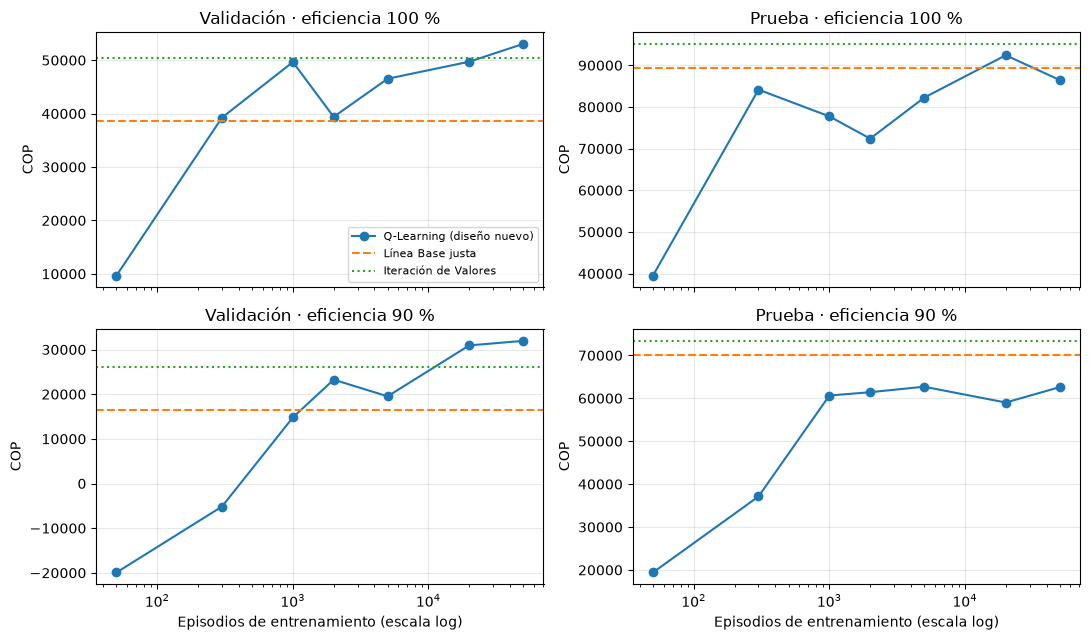

In [15]:
fig, ax = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
for fila_ax, eta_pct in zip(ax, (100, 90)):
    sub = curva[curva["eficiencia_pct"] == eta_pct]
    for eje, per, nombre in ((fila_ax[0], "validacion", "validación"), (fila_ax[1], "prueba", "prueba")):
        eje.plot(sub["episodios"], sub[f"ql_{per}"], marker="o", label="Q-Learning (diseño nuevo)")
        eje.axhline(sub[f"base_{per}"].iloc[0], color="tab:orange", ls="--", label="Línea Base justa")
        eje.axhline(sub[f"ref_{per}"].iloc[0], color="tab:green", ls=":", label="Iteración de Valores")
        eje.set_xscale("log"); eje.grid(alpha=0.3)
        eje.set_title(f"{nombre.capitalize()} · eficiencia {eta_pct} %"); eje.set_ylabel("COP")
for eje in ax[1]:
    eje.set_xlabel("Episodios de entrenamiento (escala log)")
ax[0][0].legend(fontsize=8); plt.tight_layout(); plt.show()

In [16]:
# Comprobación: simular() (lo que usa el dashboard) reproduce los escenarios con eficiencia 90 %.
for nombre, n in ESCENARIOS_EPISODIOS.items():
    fila_c = curva[(curva["eficiencia_pct"] == 90) & (curva["episodios"] == n)].iloc[0]
    r = simular(4.0, escenario=nombre, eficiencia=0.9)
    assert np.isclose(r.ahorro_qlearning_cop, fila_c.ql_prueba), nombre
    assert np.isclose(r.ahorro_base_cop, fila_c.base_prueba), nombre
    assert np.isclose(r.ahorro_referencia_cop, fila_c.ref_prueba), nombre
print("simular() reproduce los tres escenarios con eficiencia 90 %.")

simular() reproduce los tres escenarios con eficiencia 90 %.
